In [109]:
import pandas as pd
import numpy as np
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor


In [110]:
train=pd.read_csv("../data/raw/Train.csv")
test=pd.read_csv("../data/raw/Test.csv")
submissions=pd.read_csv("../data/raw/SampleSubmission.csv")

In [111]:
train["time"]=pd.to_datetime(train["time"])
test["time"]=pd.to_datetime(test["time"])

In [112]:
train["month"]=train["time"].dt.month
test["month"]=test["time"].dt.month

In [113]:
train["month_sin"]=np.sin(2*np.pi*train["month"]/12)
train["month_cos"]=np.cos(2*np.pi*train["month"]/12)
test["month_sin"]=np.sin(2*np.pi*test["month"]/12)
test["month_cos"]=np.cos(2*np.pi*test["month"]/12)



In [114]:
train["year"] = train["time"].dt.year
test["year"] = test["time"].dt.year

In [115]:
train["water_soil"] = train["TWS_t"] * train["SOIL_MOISTURE_t"]
test["water_soil"] = test["TWS_t"] * test["SOIL_MOISTURE_t"]

In [116]:
train = train.sort_values(["lat", "lon", "time"])
test = test.sort_values(["lat", "lon", "time"])

In [117]:
train["TWS_lag1"] = (
    train.groupby(["lat", "lon"])["TWS_t"].shift(1)
)

test["TWS_lag1"] = (
    test.groupby(["lat", "lon"])["TWS_t"].shift(1)
)

In [118]:
train["TWS_lag1"] = train["TWS_lag1"].fillna(train["TWS_t"])
test["TWS_lag1"] = test["TWS_lag1"].fillna(test["TWS_t"])

In [119]:
X=train.drop(columns=["sample_id","target","time"])
y=train["target"]
X_test=test[X.columns]

In [120]:
X_train,X_val,y_train,y_val=train_test_split(X,y,random_state=42,test_size=0.2)

In [121]:
numeric_cols=train.select_dtypes(include="number")
corr=numeric_cols.corr()
corr

,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month_sin,month_cos,target,month,year,water_soil,TWS_lag1
lat,1.000000,-0.061257,0.146846,0.009216,0.021361,0.027308,0.026132,0.003581,-0.000790,-0.000358,0.144698,0.000621,-0.000155,-0.050116,0.149831
lon,-0.061257,1.000000,-0.049092,-0.002677,-0.005467,-0.001542,0.005908,-0.007945,0.000710,-0.000759,-0.045923,-0.000656,0.000227,0.045243,-0.048772
TWS_t,0.146846,-0.049092,1.000000,0.235184,0.325756,0.370883,0.401171,0.356521,-0.012188,0.011508,0.803260,0.007843,-0.122653,-0.003874,0.794200
SPEI_01_t,0.009216,-0.002677,0.235184,1.000000,0.595711,0.430912,0.295543,0.371164,0.009229,0.002867,0.203882,-0.008443,-0.001785,0.022913,0.085761
SPEI_03_t,0.021361,-0.005467,0.325756,0.595711,1.000000,0.704158,0.494342,0.491131,0.015292,0.003724,0.285371,-0.010000,-0.007579,0.029122,0.254778
SPEI_06_t,0.027308,-0.001542,0.370883,0.430912,0.704158,1.000000,0.697698,0.546254,0.011550,-0.002109,0.368248,-0.008379,-0.012311,0.037359,0.313022
SPEI_12_t,0.026132,0.005908,0.401171,0.295543,0.494342,0.697698,1.000000,0.568390,-0.000204,0.002718,0.379573,0.001273,-0.020074,0.053977,0.380621
SOIL_MOISTURE_t,0.003581,-0.007945,0.356521,0.371164,0.491131,0.546254,0.568390,1.000000,0.006139,-0.000773,0.320483,-0.004421,0.009560,0.033674,0.300361
month_sin,-0.000790,0.000710,-0.012188,0.009229,0.015292,0.011550,-0.000204,0.006139,1.000000,-0.025725,-0.016912,-0.754250,0.075256,-0.028984,-0.005903
month_cos,-0.000358,-0.000759,0.011508,0.002867,0.003724,-0.002109,0.002718,-0.000773,-0.025725,1.000000,0.002764,0.231729,-0.067243,0.007933,0.017656


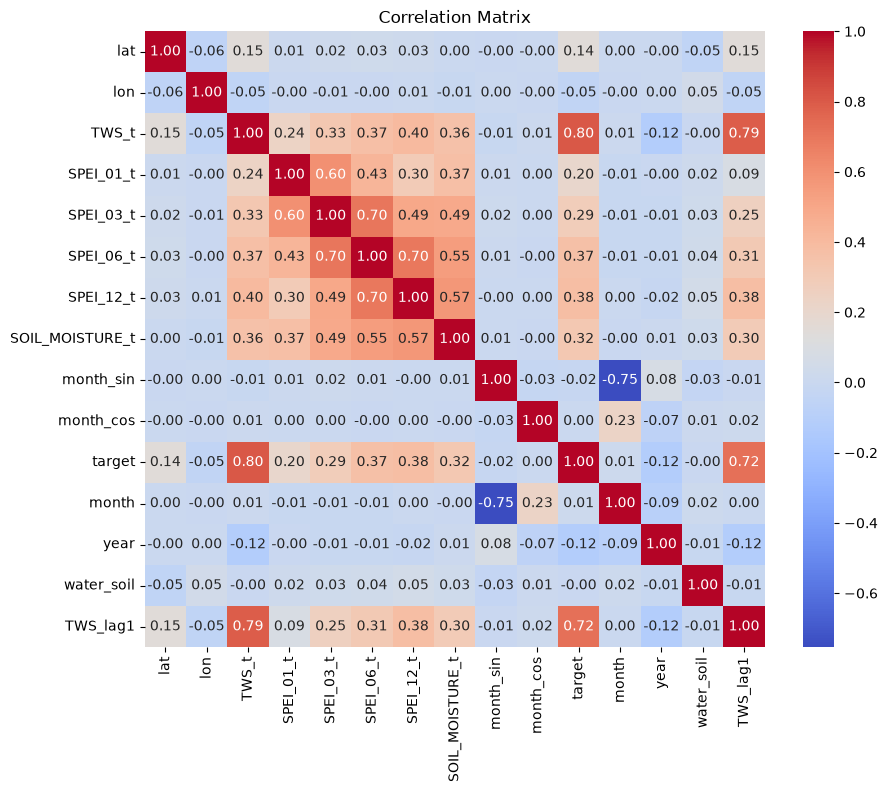

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [123]:
model = XGBRegressor(
    random_state=42,
    n_estimators=400,
    learning_rate=0.10,
    max_depth=9
)

In [124]:
model.fit(X_train,y_train)
pred=model.predict(X_val)
rmse=root_mean_squared_error(y_val,pred)
print(f"RMSE: {rmse:.4f}")

RMSE: 0.3528


In [125]:
corr["target"].sort_values(ascending=False)

target             1.000000
TWS_t              0.803260
TWS_lag1           0.720417
SPEI_12_t          0.379573
SPEI_06_t          0.368248
SOIL_MOISTURE_t    0.320483
SPEI_03_t          0.285371
SPEI_01_t          0.203882
lat                0.144698
month              0.014622
month_cos          0.002764
water_soil        -0.004759
month_sin         -0.016912
lon               -0.045923
year              -0.122804
Name: target, dtype: float64

In [126]:
importance = (
    pd.DataFrame({
        "Feature": X.columns,
        "Importance": model.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

importance

,Feature,Importance
2,TWS_t,0.803617
13,TWS_lag1,0.034145
11,year,0.021698
9,month_cos,0.020346
10,month,0.018292
8,month_sin,0.017488
5,SPEI_06_t,0.016712
1,lon,0.016434
0,lat,0.016416
6,SPEI_12_t,0.007644


<Axes: ylabel='Feature'>

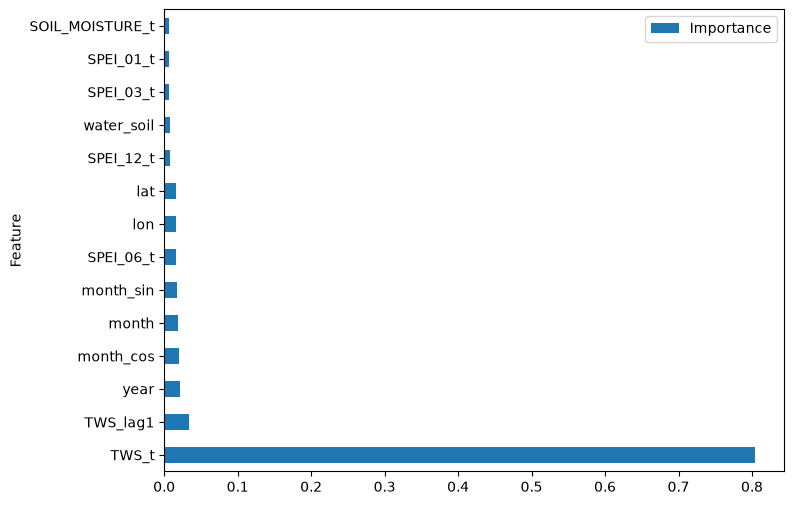

In [127]:
importance.plot.barh(
    x="Feature",
    y="Importance",
    figsize=(8,6)
)

In [128]:
train.groupby(["lat", "lon"]).size().describe()

count    15715.000000
mean       137.067833
std          6.559213
min         11.000000
25%        138.000000
50%        138.000000
75%        138.000000
max        138.000000
dtype: float64

In [129]:
train.groupby(["lat", "lon"]).size().head(10)

lat    lon  
-55.5  -68.5    138
       -67.5    138
-54.5  -71.5    138
       -70.5    138
       -69.5    138
       -68.5    138
       -67.5    138
       -66.5    138
-53.5  -73.5    138
       -72.5    138
dtype: int64